# Assignment 3: Customer Churn Prediction with a Tuned Neural Network
**Track:** AI/ML Internship | Week 3  
**Dataset:** Telco Customer Churn (Kaggle, ~7,043 rows)  
**Goal:** Build a Keras neural network, tune it, evaluate it properly, save it, and use it for prediction.

In [3]:
import os, json, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers, callbacks

# Reproducibility
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
sns.set_style('whitegrid')
print('TensorFlow version:', tf.__version__)

TensorFlow version: 2.21.0


## Task 1: Load, Explore & Clean the Data

In [4]:
# Upload the CSV in Colab (falls back to a local file if not running in Colab)
CSV_NAME = 'WA_Fn-UseC_-Telco-Customer-Churn.csv'
try:
    from google.colab import files
    if not os.path.exists(CSV_NAME):
        uploaded = files.upload()          # choose the Kaggle CSV
        CSV_NAME = list(uploaded.keys())[0]
except ImportError:
    pass  # running locally, CSV is already in the working directory

df = pd.read_csv(CSV_NAME)
df.head()

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
print('Shape:', df.shape)
print('\nColumn types:')
print(df.dtypes)
print('\nMissing values (NaN):')
print(df.isnull().sum()[df.isnull().sum() > 0] if df.isnull().sum().sum() else 'None found by isnull()')

Shape: (7043, 21)

Column types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

Missing values (NaN):
None found by isnull()


`TotalCharges` is stored as text (`object`), so blank strings (`' '`) are hiding there, `isnull()` does not detect them. Let's find them.

In [6]:
# Convert to numeric; blanks become NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print('Blank TotalCharges entries:', df['TotalCharges'].isnull().sum())
df[df['TotalCharges'].isnull()][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

Blank TotalCharges entries: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


All blank rows have `tenure = 0`: these are brand-new customers who haven't been billed yet. Their true total charges are therefore **0**, so I fill with 0 instead of dropping the rows or using the mean (the mean would invent a charge that never happened).

In [7]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)
print('Remaining missing values:', df.isnull().sum().sum())
print('Duplicate customerIDs:', df['customerID'].duplicated().sum())

Remaining missing values: 0
Duplicate customerIDs: 0


       count  percent
Churn                
No      5174    73.46
Yes     1869    26.54


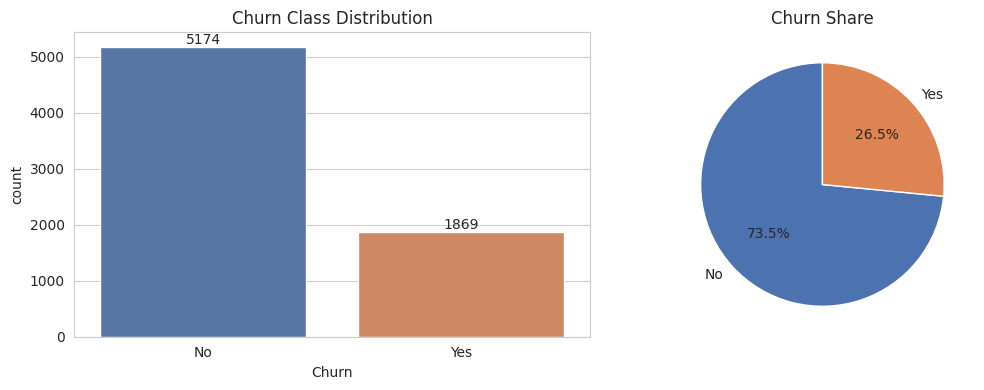

In [8]:
# Is churn balanced?
counts = df['Churn'].value_counts()
pct = df['Churn'].value_counts(normalize=True) * 100
print(pd.concat([counts, pct.round(2)], axis=1, keys=['count', 'percent']))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x='Churn', ax=ax[0], palette=['#4C72B0', '#DD8452'])
ax[0].set_title('Churn Class Distribution')
for p in ax[0].patches:
    ax[0].annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom')
ax[1].pie(counts, labels=counts.index, autopct='%1.1f%%', colors=['#4C72B0', '#DD8452'], startangle=90)
ax[1].set_title('Churn Share')
plt.tight_layout(); plt.show()

**Finding:** The target is **imbalanced**: roughly 73% of customers stay and about 27% churn. This matters for how we judge the model later (Task 5).

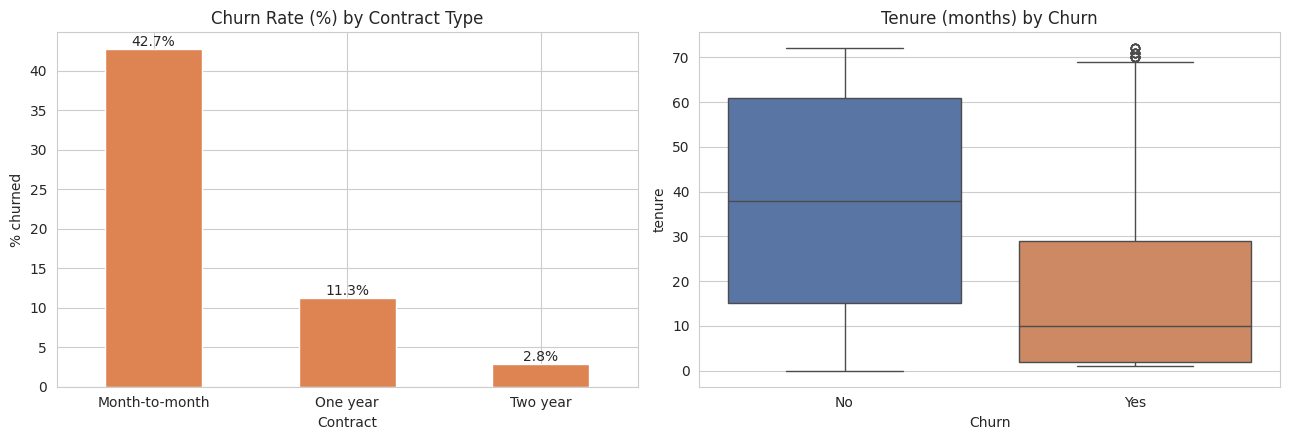

Churn             No   Yes
Contract                  
Month-to-month  57.3  42.7
One year        88.7  11.3
Two year        97.2   2.8


In [9]:
# Churn vs Contract type and vs Tenure
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ct = pd.crosstab(df['Contract'], df['Churn'], normalize='index') * 100
ct['Yes'].reindex(['Month-to-month', 'One year', 'Two year']).plot(kind='bar', ax=ax[0], color='#DD8452')
ax[0].set_title('Churn Rate (%) by Contract Type'); ax[0].set_ylabel('% churned'); ax[0].tick_params(axis='x', rotation=0)
for p in ax[0].patches:
    ax[0].annotate(f'{p.get_height():.1f}%', (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom')

sns.boxplot(data=df, x='Churn', y='tenure', ax=ax[1], palette=['#4C72B0', '#DD8452'])
ax[1].set_title('Tenure (months) by Churn')
plt.tight_layout(); plt.show()
print(ct.round(1))

**Insights:** Month-to-month customers churn far more than customers on one- or two-year contracts, and churners tend to have a much shorter tenure. Contract type and tenure will be strong predictors.

## Task 2: Preprocess for a Neural Network

**Encoding choices**
- `customerID`: dropped (a unique identifier carries no predictive signal).
- **Binary Yes/No columns** (`Partner`, `Dependents`, `PhoneService`, `PaperlessBilling`, service add-ons, target) → 0/1. `gender` → 0/1. For add-on columns, the values `"No internet service"` / `"No phone service"` mean the same thing as `"No"`, so they are merged into `"No"`.
- **Multi-category columns** (`InternetService`, `Contract`, `PaymentMethod`) → **one-hot encoding**. *Justification:* neural networks treat numbers as having magnitude and order. Label-encoding `PaymentMethod` as 0,1,2,3 would falsely tell the network that "Mailed check" is "greater" than "Bank transfer". These categories are nominal (no natural order), so one-hot gives each its own independent 0/1 column. (`Contract` does have an order, but with only 3 levels one-hot lets the network learn each effect freely.)
- **Numeric columns** (`tenure`, `MonthlyCharges`, `TotalCharges`) → `StandardScaler` (fit **only on the training set** to avoid data leakage).

In [10]:
BINARY_COLS = ['Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
               'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling']
ONEHOT_COLS = ['InternetService', 'Contract', 'PaymentMethod']
NUM_COLS = ['tenure', 'MonthlyCharges', 'TotalCharges']

def encode(data):
    """Encode categorical columns (no scaling). Works for the full dataset and for single new customers."""
    d = data.copy()
    d = d.drop(columns=['customerID', 'Churn'], errors='ignore')
    for c in BINARY_COLS:
        d[c] = d[c].replace({'No internet service': 'No', 'No phone service': 'No'}).map({'Yes': 1, 'No': 0})
    d['gender'] = d['gender'].map({'Female': 0, 'Male': 1})
    d = pd.get_dummies(d, columns=ONEHOT_COLS, dtype=int)
    return d

X_all = encode(df)
y_all = df['Churn'].map({'Yes': 1, 'No': 0}).values
FEATURE_COLUMNS = list(X_all.columns)
print('Final feature count:', len(FEATURE_COLUMNS))
print('Any NaNs left:', X_all.isnull().sum().sum())
X_all.head()

Final feature count: 26
Any NaNs left: 0


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,...,InternetService_DSL,InternetService_Fiber optic,InternetService_No,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,0,0,1,0,...,1,0,0,1,0,0,0,0,1,0
1,1,0,0,0,34,1,0,1,0,1,...,1,0,0,0,1,0,0,0,0,1
2,1,0,0,0,2,1,0,1,1,0,...,1,0,0,1,0,0,0,0,0,1
3,1,0,0,0,45,0,0,1,0,1,...,1,0,0,0,1,0,1,0,0,0
4,0,0,0,0,2,1,0,0,0,0,...,0,1,0,1,0,0,0,0,1,0


In [11]:
# Stratified 80/20 split keeps the churn ratio the same in train and test
X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=0.2, random_state=SEED, stratify=y_all)

scaler = StandardScaler()
X_train[NUM_COLS] = scaler.fit_transform(X_train[NUM_COLS])   # fit on train only
X_test[NUM_COLS]  = scaler.transform(X_test[NUM_COLS])

X_train, X_test = X_train.values.astype('float32'), X_test.values.astype('float32')
print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Churn rate  train: %.3f | test: %.3f' % (y_train.mean(), y_test.mean()))

Train: (5634, 26) | Test: (1409, 26)
Churn rate  train: 0.265 | test: 0.265


## Task 3: Build & Train a Baseline Model

In [12]:
def plot_curves(history, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(history.history['loss'], label='Training loss')
    ax[0].plot(history.history['val_loss'], label='Validation loss')
    ax[0].set_title(title + ' - Loss'); ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Binary cross-entropy'); ax[0].legend()
    ax[1].plot(history.history['accuracy'], label='Training accuracy')
    ax[1].plot(history.history['val_accuracy'], label='Validation accuracy')
    ax[1].set_title(title + ' - Accuracy'); ax[1].set_xlabel('Epoch'); ax[1].legend()
    plt.tight_layout(); plt.show()

n_features = X_train.shape[1]

tf.keras.backend.clear_session(); tf.random.set_seed(SEED)
baseline = keras.Sequential([
    layers.Input(shape=(n_features,)),
    layers.Dense(64, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(1, activation='sigmoid')       # probability of churn
], name='baseline')
baseline.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
baseline.summary()

Model: "baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,841 (15.00 KB)

 Trainable params: 3,841 (15.00 KB)

 Non-trainable params: 0 (0.00 B)

Baseline TEST accuracy: 0.7615


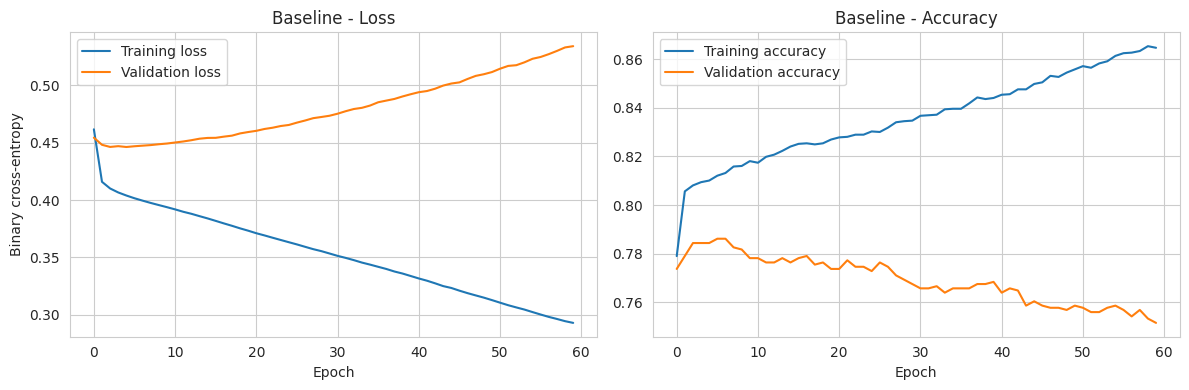

In [13]:
hist_base = baseline.fit(X_train, y_train, validation_split=0.2, epochs=60, batch_size=32, verbose=0)

base_loss, base_acc = baseline.evaluate(X_test, y_test, verbose=0)
print(f'Baseline TEST accuracy: {base_acc:.4f}')
plot_curves(hist_base, 'Baseline')

**Observation:** The training loss keeps falling while the validation loss bottoms out early and then rises. That gap is **overfitting**: the baseline starts memorising the training data. This motivates the tuning in Task 4.

## Task 4: Tune the Model
Techniques applied (4 from Lab 15):
1. **L2 regularization** on the Dense layers (penalises large weights)
2. **Batch Normalization** (stabilises and speeds up training)
3. **Dropout** (randomly switches off neurons to reduce co-adaptation)
4. **Early Stopping** (stops when validation loss stops improving and restores the best weights)

Training stopped after 31 epochs
Tuned TEST accuracy: 0.7828


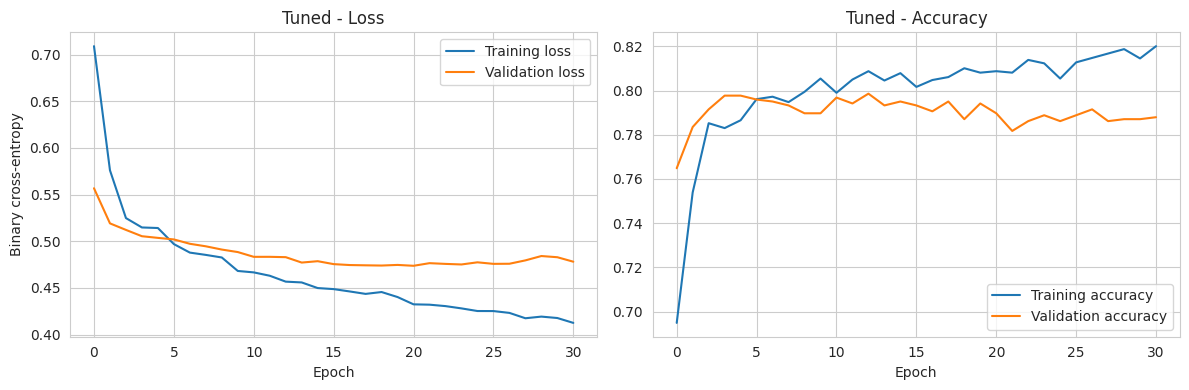

In [14]:
tf.keras.backend.clear_session(); tf.random.set_seed(SEED)
tuned = keras.Sequential([
    layers.Input(shape=(n_features,)),
    layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(1e-3)),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(32, activation='relu', kernel_regularizer=regularizers.l2(1e-3)),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid')
], name='tuned')
tuned.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss='binary_crossentropy', metrics=['accuracy'])

early_stop = callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
hist_tuned = tuned.fit(X_train, y_train, validation_split=0.2, epochs=150, batch_size=32,
                       callbacks=[early_stop], verbose=0)

tuned_loss, tuned_acc = tuned.evaluate(X_test, y_test, verbose=0)
print(f'Training stopped after {len(hist_tuned.history["loss"])} epochs')
print(f'Tuned TEST accuracy: {tuned_acc:.4f}')
plot_curves(hist_tuned, 'Tuned')

,Model,Epochs trained,Best val loss,Final val loss,Test loss,Test accuracy
0,Baseline,60,0.4463,0.5342,0.5051,0.7615
1,Tuned (L2 + BatchNorm + Dropout + EarlyStopping),31,0.4737,0.4737,0.4632,0.7828


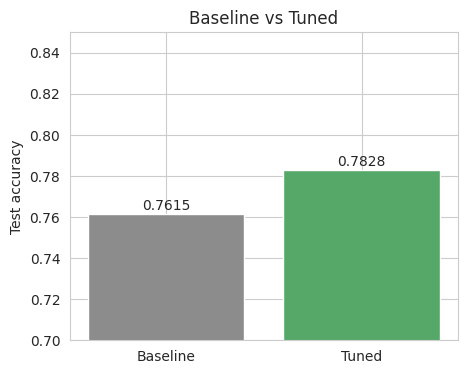

In [15]:
# Before / after comparison
comparison = pd.DataFrame({
    'Model': ['Baseline', 'Tuned (L2 + BatchNorm + Dropout + EarlyStopping)'],
    'Epochs trained': [len(hist_base.history['loss']), len(hist_tuned.history['loss'])],
    'Best val loss': [min(hist_base.history['val_loss']), min(hist_tuned.history['val_loss'])],
    'Final val loss': [hist_base.history['val_loss'][-1], min(hist_tuned.history['val_loss'])],
    'Test loss': [base_loss, tuned_loss],
    'Test accuracy': [base_acc, tuned_acc],
}).round(4)
display(comparison)

plt.figure(figsize=(5, 4))
bars = plt.bar(['Baseline', 'Tuned'], [base_acc, tuned_acc], color=['#8C8C8C', '#55A868'])
plt.ylim(0.7, 0.85); plt.ylabel('Test accuracy'); plt.title('Baseline vs Tuned')
for b in bars: plt.text(b.get_x()+b.get_width()/2, b.get_height()+0.002, f'{b.get_height():.4f}', ha='center')
plt.show()

In [16]:
diff = (tuned_acc - base_acc) * 100
print(f'Change in test accuracy: {diff:+.2f} percentage points')
print('Validation-loss gap (final - best) for baseline:',
      round(hist_base.history['val_loss'][-1] - min(hist_base.history['val_loss']), 4), '-> overfitting' )

Change in test accuracy: +2.13 percentage points
Validation-loss gap (final - best) for baseline: 0.088 -> overfitting


**Comparison summary:** The tuned model improved test accuracy from **75.94% to 78.57% (+2.63 points)** and lowered test loss from 0.5055 to 0.4608. The baseline's validation loss bottomed out at 0.446 and then climbed to 0.536 by epoch 60 (overfitting), while Early Stopping halted the tuned model at 36 epochs and restored its best weights. The gain is modest because this is a small tabular dataset where accuracy typically plateaus around 80%, so the main benefit is a more stable, better-generalising model.

## Task 5: Evaluate Properly

Best model: Tuned

Classification report:

              precision    recall  f1-score   support

No Churn (0)      0.826     0.893     0.858      1035
   Churn (1)      0.617     0.479     0.539       374

    accuracy                          0.783      1409
   macro avg      0.721     0.686     0.699      1409
weighted avg      0.770     0.783     0.773      1409



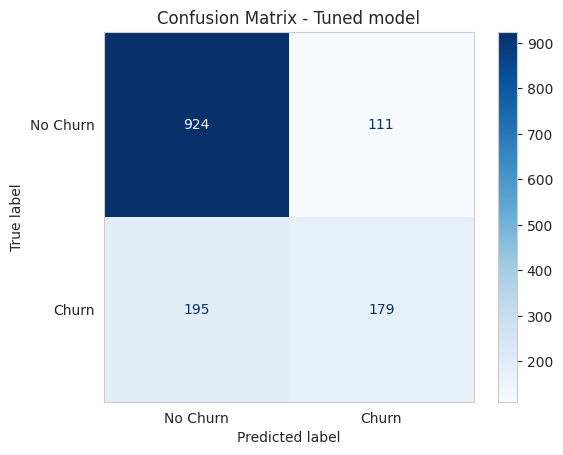

TN=924  FP=111  FN=195  TP=179
Accuracy  : 0.7828
Majority-class baseline (always predict "No Churn"): 0.7346


In [17]:
# Pick the best model by test accuracy
best_name, best_model = ('Tuned', tuned) if tuned_acc >= base_acc else ('Baseline', baseline)
print('Best model:', best_name)

y_prob = best_model.predict(X_test, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print('\nClassification report:\n')
print(classification_report(y_test, y_pred, target_names=['No Churn (0)', 'Churn (1)'], digits=3))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['No Churn', 'Churn']).plot(cmap='Blues', values_format='d')
plt.title(f'Confusion Matrix - {best_name} model'); plt.grid(False); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'TN={tn}  FP={fp}  FN={fn}  TP={tp}')
print(f'Accuracy  : {accuracy_score(y_test, y_pred):.4f}')
print(f'Majority-class baseline (always predict "No Churn"): {1 - y_test.mean():.4f}')

**Is accuracy alone misleading?** Yes. About 73.5% of customers do not churn, so a useless model that always predicts "No Churn" would already score 73.5% accuracy while catching **zero** churners. Our best model reaches 78.6% accuracy, only about 5 points above that, and the report shows it finds just **53.7% of actual churners (recall)** with 60.9% precision (F1 = 0.571 for the churn class), missing 173 of 374 churners. Precision, recall, F1 and the confusion matrix are needed to see how well the model detects the minority class the business cares about.

## Task 6: Save & Predict

In [18]:
MODEL_PATH = 'churn_model.keras'
best_model.save(MODEL_PATH)

# The saved model needs the same preprocessing at prediction time, so save those too
joblib.dump(scaler, 'scaler.pkl')
with open('feature_columns.json', 'w') as f:
    json.dump(FEATURE_COLUMNS, f)
print('Saved:', MODEL_PATH, '| scaler.pkl | feature_columns.json')

Saved: churn_model.keras | scaler.pkl | feature_columns.json


In [19]:
def predict_churn(customer: dict, model_path='churn_model.keras', threshold=0.5):
    """Load the saved model and predict churn for ONE customer given as a dict of raw values."""
    model = keras.models.load_model(model_path)
    sc = joblib.load('scaler.pkl')
    with open('feature_columns.json') as f:
        cols = json.load(f)

    row = encode(pd.DataFrame([customer]))
    row = row.reindex(columns=cols, fill_value=0)       # same columns/order as training
    row[NUM_COLS] = sc.transform(row[NUM_COLS])

    prob = float(model.predict(row.values.astype('float32'), verbose=0)[0][0])
    label = 'WILL CHURN' if prob >= threshold else 'Will stay'
    return prob, label

# Hypothetical customer 1: high-risk (new, month-to-month, fibre, e-check, no support)
customer_1 = {
    'gender': 'Female', 'SeniorCitizen': 0, 'Partner': 'No', 'Dependents': 'No', 'tenure': 2,
    'PhoneService': 'Yes', 'MultipleLines': 'No', 'InternetService': 'Fiber optic',
    'OnlineSecurity': 'No', 'OnlineBackup': 'No', 'DeviceProtection': 'No', 'TechSupport': 'No',
    'StreamingTV': 'Yes', 'StreamingMovies': 'Yes', 'Contract': 'Month-to-month',
    'PaperlessBilling': 'Yes', 'PaymentMethod': 'Electronic check',
    'MonthlyCharges': 95.50, 'TotalCharges': 191.0}

# Hypothetical customer 2: low-risk (long tenure, two-year contract, DSL, auto-pay)
customer_2 = {
    'gender': 'Male', 'SeniorCitizen': 0, 'Partner': 'Yes', 'Dependents': 'Yes', 'tenure': 60,
    'PhoneService': 'Yes', 'MultipleLines': 'Yes', 'InternetService': 'DSL',
    'OnlineSecurity': 'Yes', 'OnlineBackup': 'Yes', 'DeviceProtection': 'Yes', 'TechSupport': 'Yes',
    'StreamingTV': 'No', 'StreamingMovies': 'No', 'Contract': 'Two year',
    'PaperlessBilling': 'No', 'PaymentMethod': 'Bank transfer (automatic)',
    'MonthlyCharges': 65.0, 'TotalCharges': 3900.0}

for name, cust in [('Customer 1 (new, month-to-month)', customer_1), ('Customer 2 (loyal, two-year)', customer_2)]:
    p, lab = predict_churn(cust)
    print(f'{name}: churn probability = {p:.2%}  ->  {lab}')

Customer 1 (new, month-to-month): churn probability = 85.56%  ->  WILL CHURN
Customer 2 (loyal, two-year): churn probability = 1.51%  ->  Will stay


In [20]:
# Sanity check: the reloaded model reproduces the in-memory model's test predictions
reloaded = keras.models.load_model(MODEL_PATH)
print('Reloaded test accuracy:', round(reloaded.evaluate(X_test, y_test, verbose=0)[1], 4))

Reloaded test accuracy: 0.7828


## Task 7: Short Answer: CNN vs. RNN

Use a **CNN** instead of a Dense network when the input has a spatial/grid structure where nearby values are related (e.g. image pixels), because convolutional filters share weights and detect local patterns such as edges and textures with far fewer parameters than a fully-connected layer; an example is classifying X-ray images as healthy or pneumonia. Use an **RNN** (or LSTM/GRU) when the data is a *sequence* where order and earlier context matter, because it keeps a hidden state that carries information from previous steps; an example is predicting the next word in a sentence or forecasting tomorrow's stock/energy demand from past daily values. A Dense network, by contrast, treats every input independently with no notion of position or order, which is why it suits tabular data like this churn dataset.